In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import numpy as np
from scipy.optimize import root_scalar

In [ ]:
# def lin funtion to fit to  P - I curve
def lin(x, k, d):
    return k*x + d


      converged: True
           flag: converged
 function_calls: 3
     iterations: 2
           root: 36.93229519703761
         method: brentq

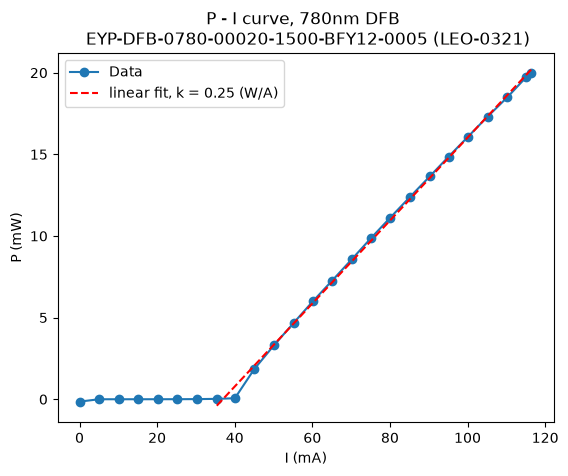

In [39]:
# P vs I curve 780nm Laser
data_path = "/home/mmaurer/Documents/ISTA_PhD_Local/Rotations/Leonard_Group_Rotation_1/Local-Data/P-I_Curve_780nm_DFB_12_10_2026.csv"
datadir = "/home/mmaurer/Documents/ISTA_PhD_Local/Rotations/Leonard_Group_Rotation_1/Local-Data"
data = pd.read_csv(data_path)

popt, pcov = curve_fit(lin, np.array(data['I (mA)'])[7::], np.array(data['P (mW)'])[7::])


fig, ax  = plt.subplots()

ax.plot(data['I (mA)'], data['P (mW)'], marker = 'o', label = "Data")
ax.set_title("P - I curve, 780nm DFB \n EYP-DFB-0780-00020-1500-BFY12-0005 (LEO-0321)")
ax.set_xlabel("I (mA)")
ax.set_ylabel("P (mW)")
ax.plot(data['I (mA)'][7::], lin(np.array(data['I (mA)'])[7::], popt[0], popt[1]), label= f"linear fit, k = {popt[0]:.2f} (W/A)", ls = "--", color ="red")
ax.legend()
fig.savefig(datadir + "P-I_curve.png")



result = root_scalar(
    lin,
    bracket=[30, 50],
    method='brentq',
    args=(popt[0], popt[1]),  # This freezes y and z
)
result